# 03 · LSTM encoder–decoder (E6)

The deep model from the paper, adapted to day-ahead and built so it can't leak:
- **Samples** come from `features/sequences.py`, which builds on the same as-of views as the tabular builder. Its own leakage test (future poisoning) passes, and it fails when a leak is planted.
- **Encoder:** the 168 known hours up to the load cutoff: load / level, a missing-value mask, temperature, clock.
- **Decoder:** each target hour's forecast temperature, clock, holiday flag, lead.
- **Output:** load / level per hour, so it's the same ratio idea as the tabular `ratio` target.
- **Data:** trained on `obs` (ERA5) samples and validated on `proxy` (forecast) samples, with the same 3 folds and the same scoring as notebooks 01–02.

Floor: `same_hour_latest`, 8.18% MAPE / 6.50% Peak-MAPE.

In [1]:
%matplotlib inline
import time, warnings, tempfile
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
from shef import store
from shef.features import sequences
from shef.models import folds, lstm, plots, report, tracking
from shef.models.metrics import score_folds

mlflow = tracking.init()
joined = store.read("clean", "joined")
t0 = time.time()
seq = {
    "obs": sequences.build(joined, folds.TRAIN_START, folds.FOLDS[-1].val_end, "obs"),
    "proxy": sequences.build(joined, folds.FOLDS[0].val_start, folds.FOLDS[-1].val_end, "proxy"),
}
print(f"built in {time.time()-t0:.0f}s", {k: len(v) for k, v in seq.items()})

built in 255s {'obs': 3498, 'proxy': 1096}


## Train and validate, fold by fold

In [2]:
HP = dict(hidden=64, layers=1, dropout=0.1, lr=2e-3, epochs=60, batch=64, patience=8)
parts, info, models = [], {}, {}
for f in folds.FOLDS:
    tr = lstm.subset(seq["obs"], folds.train_mask(lstm.target_days(seq["obs"]), f).to_numpy())
    va = lstm.subset(seq["proxy"], folds.val_mask(lstm.target_days(seq["proxy"]), f).to_numpy())
    model, scaler, inf = lstm.fit(tr, **HP)
    rows = lstm.to_rows(va, lstm.predict(model, scaler, va), f.id)
    parts.append(rows); info[f.id] = inf; models[f.id] = (model, scaler)
    m = score_folds(rows)
    print(f"fold {f.id}: MAPE {m['mape']:.2f}%  peak {m['peak_mape']:.2f}%  "
          f"({len(tr)} train / {len(va)} val samples, {inf['epochs']} epochs, {inf['seconds']:.0f}s)")
scored = pd.concat(parts, ignore_index=True)
report.summary(scored, ["pred"]).rename(index={"pred": "lstm"})

fold 1: MAPE 5.34%  peak 8.49%  (2394 train / 365 val samples, 46 epochs, 122s)


fold 2: MAPE 5.86%  peak 9.36%  (2759 train / 366 val samples, 25 epochs, 69s)


fold 3: MAPE 5.81%  peak 4.70%  (3125 train / 365 val samples, 25 epochs, 68s)


,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape
lstm,5.67,7.52,739.58,0.88,5.34,5.86,5.81


Training time decides the GPU question. The plan's threshold is about 30 minutes per run.

In [3]:
total_min = sum(i["seconds"] for i in info.values()) / 60
print(f"total training time: {total_min:.1f} min on {torch.get_num_threads()} CPU threads")

total training time: 4.3 min on 4 CPU threads


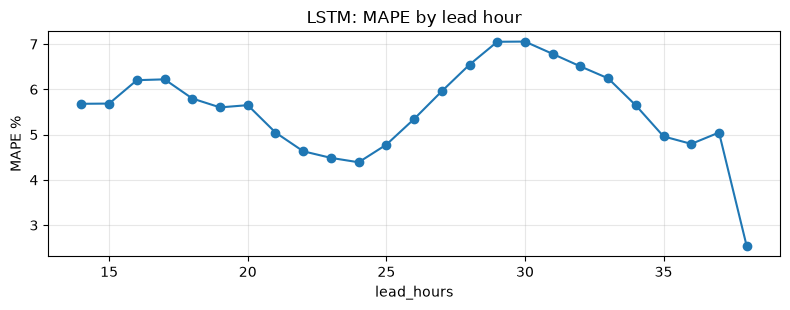

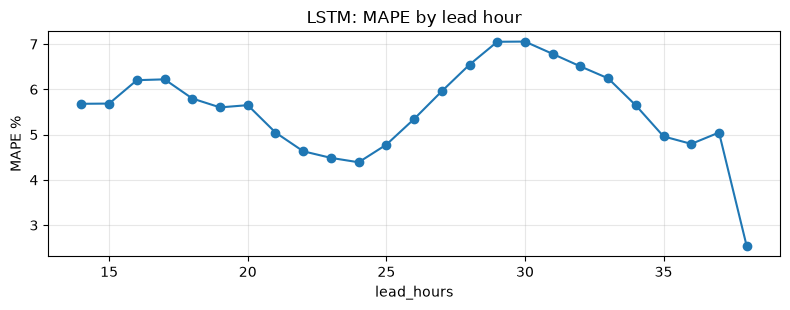

In [4]:
plots.error_by(scored, "lead_hours", "pred", "LSTM: MAPE by lead hour")

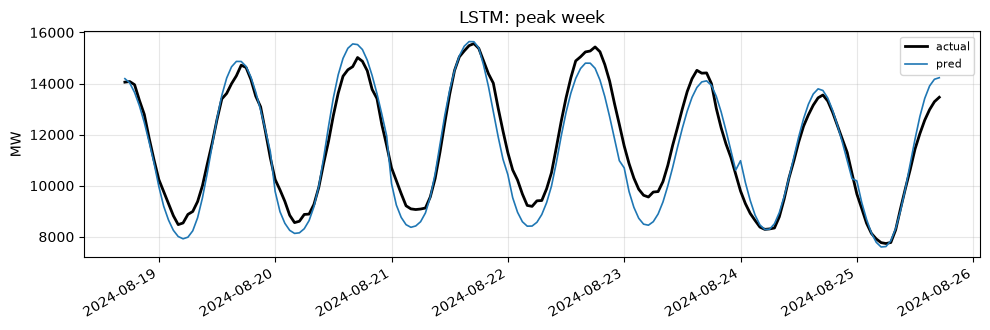

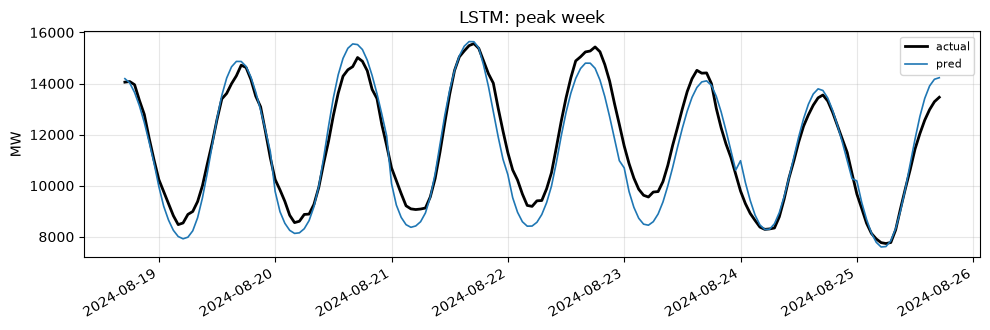

In [5]:
plots.peak_week(scored, ["pred"], "LSTM: peak week")

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    path = f"{tmp}/lstm_fold3.pt"
    torch.save({"state_dict": models[3][0].state_dict(), "scaler": models[3][1].__dict__, "hp": HP}, path)
    report.log_scored("E6_lstm_seq2seq", scored, "pred",
                      {"model": "lstm_seq2seq", "target": "ratio", "train_source": "obs", "uri": "exclude", **HP,
                       "enc_features": sequences.ENC_FEATURES, "dec_features": sequences.DEC_FEATURES,
                       "train_minutes": round(total_min, 1)},
                      dicts={"training": {str(k): v for k, v in info.items()}}, files={"model": path},
                      tags={"experiment": "E6"})
print("logged")

🏃 View run E6_lstm_seq2seq at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/8196de595e604cecbaa26b36ccd788aa
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


logged


## Reading

- **The LSTM scores 5.67% MAPE but 7.52% Peak-MAPE.**
  - It beats the floor on average (8.18%) but is worse than it at peaks (6.50%), so it fails the champion rule on its own.
  - The best trees reach 4.84–4.85% MAPE with 3.3–3.8% Peak-MAPE.
- **It has different strengths from the trees.**
  - On fold 2, the hard Aug 2023 → Aug 2024 year, it scores 5.86% against about 6.3% for every tree model.
  - It's weaker on folds 1 and 3 (5.3–5.8% vs about 4.0–4.2%).
  - Errors that differ like this are what an ensemble can use, so it goes into E7 as a candidate member.
- **Peaks are its weak spot.** Fold 1 Peak-MAPE is 8.49% and fold 2 is 9.36%.
  - The decoder sees forecast temperature per hour, but not the daily max or min or the CDD-type features the trees get.
  - Adding those to the decoder is the obvious next step if the LSTM earns a place.
- **Compute:** building 3,498 + 1,096 sequence samples took 255 s, and training took 4.3 min in total on 4 CPU threads, with early stopping after 25–46 epochs. **A GPU isn't needed.**